# 2026-10-26 Nonlinear Regression

## Last time

* Discuss projects
* Gradient-based optimization for linear models
* Effect of conditioning on convergence rate

## Today
* Nonlinear models
* Computing derivatives
  * numeric
  * analytic by hand
  * algorithmic (automatic) differentiation

In [1]:
using LinearAlgebra
using Plots
default(linewidth=4, legendfontsize=12)

function vander(x, k=nothing)
    if isnothing(k)
        k = length(x)
    end
    m = length(x)
    V = ones(m, k)
    for j in 2:k
        V[:, j] = V[:, j-1] .* x
    end
    V
end

function vander_chebyshev(x, n=nothing)
    if isnothing(n)
        n = length(x) # Square by default
    end
    m = length(x)
    T = ones(m, n)
    if n > 1
        T[:, 2] = x
    end
    for k in 3:n
        #T[:, k] = x .* T[:, k-1]
        T[:, k] = 2 * x .* T[:,k-1] - T[:, k-2]
    end
    T
end

function chebyshev_regress_eval(x, xx, n)
    V = vander_chebyshev(x, n)
    vander_chebyshev(xx, n) / V
end

runge(x) = 1 / (1 + 10*x^2)
runge_noisy(x, sigma) = runge.(x) + randn(size(x)) * sigma

CosRange(a, b, n) = (a + b)/2 .+ (b - a)/2 * cos.(LinRange(-pi, 0, n))

vcond(mat, points, nmax) = [cond(mat(points(-1, 1, n))) for n in 2:nmax]

[ Info: Precompiling Plots [91a5bcdd-55d7-5caf-9e0b-520d859cae80](cache misses: wrong dep version loaded (1), incompatible header (3))
[ Info: Precompiling Plots [91a5bcdd-55d7-5caf-9e0b-520d859cae80] (cache misses: wrong dep version loaded (2), incompatible header (6))

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up
┌ Warning: Module PrecompileTools with build ID fafbfcfd-399e-1356-41bb-42c3d1824847 is missing from the cache.
│ This may mean PrecompileTools [aea7be01-6a6a-4083-8856-8a6e6704d82a] does not support precompilation but is imported by a module that does.
└ @ Base loading.jl:2709
┌ Info: Skipping precompilation due to precompilable error. Importing Plots [91a5bcdd-55d7-5caf-9e0b-520d859cae80].
└   exception = Error when precompiling module, potentially caused by a __precompile__(false) declaration in the module.
[ Info: Pre

┌ Warning: Module JLLWrappers with build ID fafbfcfd-e215-6d01-fbb6-af3c7dd41f26 is missing from the cache.
│ This may mean JLLWrappers [692b3bcd-3c85-4b1f-b108-f13ce0eb3210] does not support precompilation but is imported by a module that does.
└ @ Base loading.jl:2709
┌ Info: Skipping precompilation due to precompilable error. Importing fzf_jll [214eeab7-80f7-51ab-84ad-2988db7cef09].
└   exception = Error when precompiling module, potentially caused by a __precompile__(false) declaration in the module.
[ Info: Precompiling JSON [682c06a0-de6a-54ab-a142-c8b1cf79cde6](cache misses: wrong dep version loaded (1), incompatible header (4))
[ Info: Precompiling JSON [682c06a0-de6a-54ab-a142-c8b1cf79cde6] (cache misses: wrong dep version loaded (2), incompatible header (8))

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up
┌ Warning: Module PrecompileTools with build ID fafbfcfd-399e-1356-41bb-42c3d1824847 is missing from the cache.
│ This m

[ Info: Precompiling FriBidi_jll [559328eb-81f9-559d-9380-de523a88c83c] (cache misses: wrong dep version loaded (2), incompatible header (4))

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up
┌ Warning: Module JLLWrappers with build ID fafbfcfd-e215-6d01-fbb6-af3c7dd41f26 is missing from the cache.
│ This may mean JLLWrappers [692b3bcd-3c85-4b1f-b108-f13ce0eb3210] does not support precompilation but is imported by a module that does.
└ @ Base loading.jl:2709
┌ Info: Skipping precompilation due to precompilable error. Importing FriBidi_jll [559328eb-81f9-559d-9380-de523a88c83c].
└   exception = Error when precompiling module, potentially caused by a __precompile__(false) declaration in the module.
[ Info: Precompiling HarfBuzz_jll [2e76f6c2-a576-52d4-95c1-20adfe4de566](cache misses: wrong dep version loaded (1), incompatible header (3))
[ Info: Precompiling HarfBuzz_jll [2e76f6c2-a576-52d4-95c1-20adfe4de566] (cache misses: wrong dep ver

┌ Warning: Module JLLWrappers with build ID fafbfcfd-e215-6d01-fbb6-af3c7dd41f26 is missing from the cache.
│ This may mean JLLWrappers [692b3bcd-3c85-4b1f-b108-f13ce0eb3210] does not support precompilation but is imported by a module that does.
└ @ Base loading.jl:2709
┌ Info: Skipping precompilation due to precompilable error. Importing Pixman_jll [30392449-352a-5448-841d-b1acce4e97dc].
└   exception = Error when precompiling module, potentially caused by a __precompile__(false) declaration in the module.
[ Info: Precompiling libpng_jll [b53b4c65-9356-5827-b1ea-8c7a1a84506f](cache misses: wrong dep version loaded (1), incompatible header (3))
[ Info: Precompiling libpng_jll [b53b4c65-9356-5827-b1ea-8c7a1a84506f] (cache misses: wrong dep version loaded (2), incompatible header (6))

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up
┌ Warning: Module JLLWrappers with build ID fafbfcfd-e215-6d01-fbb6-af3c7dd41f26 is missing from the cach

┌ Info: Skipping precompilation due to precompilable error. Importing Xorg_libxcb_jll [c7cfdc94-dc32-55de-ac96-5a1b8d977c5b].
└   exception = Error when precompiling module, potentially caused by a __precompile__(false) declaration in the module.
[ Info: Precompiling Xorg_libXau_jll [0c0b7dd1-d40b-584c-a123-a41640f87eec](cache misses: wrong dep version loaded (1), incompatible header (2))
[ Info: Precompiling Xorg_libXau_jll [0c0b7dd1-d40b-584c-a123-a41640f87eec] (cache misses: wrong dep version loaded (2), incompatible header (4))

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up
┌ Warning: Module JLLWrappers with build ID fafbfcfd-e215-6d01-fbb6-af3c7dd41f26 is missing from the cache.
│ This may mean JLLWrappers [692b3bcd-3c85-4b1f-b108-f13ce0eb3210] does not support precompilation but is imported by a module that does.
└ @ Base loading.jl:2709
┌ Info: Skipping precompilation due to precompilable error. Importing Xorg_libXau_jll [0c0

...

┌ Warning: Module JLLWrappers with build ID fafbfcfd-e215-6d01-fbb6-af3c7dd41f26 is missing from the cache.
│ This may mean JLLWrappers [692b3bcd-3c85-4b1f-b108-f13ce0eb3210] does not support precompilation but is imported by a module that does.
└ @ Base loading.jl:2709
┌ Info: Skipping precompilation due to precompilable error. Importing Xorg_libSM_jll [c834827a-8449-5923-a945-d239c165b7dd].
└   exception = Error when precompiling module, potentially caused by a __precompile__(false) declaration in the module.
[ Info: Precompiling Xorg_libICE_jll [f67eecfb-183a-506d-b269-f58e52b52d7c](cache misses: wrong dep version loaded (1), incompatible header (2))
[ Info: Precompiling Xorg_libICE_jll [f67eecfb-183a-506d-b269-f58e52b52d7c] (cache misses: wrong dep version loaded (2), incompatible header (4))

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up
┌ Warning: Module JLLWrappers with build ID fafbfcfd-e215-6d01-fbb6-af3c7dd41f26 is missing

┌ Warning: Module JLLWrappers with build ID fafbfcfd-e215-6d01-fbb6-af3c7dd41f26 is missing from the cache.
│ This may mean JLLWrappers [692b3bcd-3c85-4b1f-b108-f13ce0eb3210] does not support precompilation but is imported by a module that does.
└ @ Base loading.jl:2709
┌ Info: Skipping precompilation due to precompilable error. Importing Xorg_libXrandr_jll [ec84b674-ba8e-5d96-8ba1-2a689ba10484].
└   exception = Error when precompiling module, potentially caused by a __precompile__(false) declaration in the module.
[ Info: Precompiling Wayland_jll [a2964d1f-97da-50d4-b82a-358c7fce9d89](cache misses: wrong dep version loaded (1), incompatible header (2))
[ Info: Precompiling Wayland_jll [a2964d1f-97da-50d4-b82a-358c7fce9d89] (cache misses: wrong dep version loaded (2), incompatible header (4))

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up
┌ Warning: Module JLLWrappers with build ID fafbfcfd-e215-6d01-fbb6-af3c7dd41f26 is missing fro

┌ Warning: Module JLLWrappers with build ID fafbfcfd-e215-6d01-fbb6-af3c7dd41f26 is missing from the cache.
│ This may mean JLLWrappers [692b3bcd-3c85-4b1f-b108-f13ce0eb3210] does not support precompilation but is imported by a module that does.
└ @ Base loading.jl:2709
┌ Info: Skipping precompilation due to precompilable error. Importing Dbus_jll [ee1fde0b-3d02-5ea6-8484-8dfef6360eab].
└   exception = Error when precompiling module, potentially caused by a __precompile__(false) declaration in the module.
[ Info: Precompiling Pango_jll [36c8627f-9965-5494-a995-c6b170f724f3](cache misses: wrong dep version loaded (1), incompatible header (3))
[ Info: Precompiling Pango_jll [36c8627f-9965-5494-a995-c6b170f724f3] (cache misses: wrong dep version loaded (2), incompatible header (6))

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up
┌ Warning: Module JLLWrappers with build ID fafbfcfd-e215-6d01-fbb6-af3c7dd41f26 is missing from the cache.
│

┌ Warning: Module JLLWrappers with build ID fafbfcfd-e215-6d01-fbb6-af3c7dd41f26 is missing from the cache.
│ This may mean JLLWrappers [692b3bcd-3c85-4b1f-b108-f13ce0eb3210] does not support precompilation but is imported by a module that does.
└ @ Base loading.jl:2709
┌ Info: Skipping precompilation due to precompilable error. Importing XZ_jll [ffd25f8a-64ca-5728-b0f7-c24cf3aae800].
└   exception = Error when precompiling module, potentially caused by a __precompile__(false) declaration in the module.
[ Info: Precompiling Zstd_jll [3161d3a3-bdf6-5164-811a-617609db77b4](cache misses: wrong dep version loaded (1), incompatible header (2))
[ Info: Precompiling Zstd_jll [3161d3a3-bdf6-5164-811a-617609db77b4] (cache misses: wrong dep version loaded (2), incompatible header (4))

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up
┌ Warning: Module JLLWrappers with build ID fafbfcfd-e215-6d01-fbb6-af3c7dd41f26 is missing from the cache.
│ Thi

vcond (generic function with 1 method)

## Gradient descent

Instead of solving the least squares problem using linear algebra (QR factorization), we could solve it using gradient descent.  That is, on each iteration, we'll take a step in the direction of the negative gradient.

In [2]:
function grad_descent(loss, grad, c0; gamma=1e-3, tol=1e-5)
    """Minimize loss(c) via gradient descent with initial guess c0
    using learning rate gamma.  Declares convergence when gradient
    is less than tol or after 500 steps.
    """
    c = copy(c0)
    chist = [copy(c)]
    lhist = [loss(c)]
    for it in 1:500
        g = grad(c)
        c -= gamma * g
        push!(chist, copy(c))
        push!(lhist, loss(c))
        if norm(g) < tol
            break
        end
    end
    (c, hcat(chist...), lhist)
end

grad_descent (generic function with 1 method)

## Quadratic model

cond(A) = 9.46578492882319


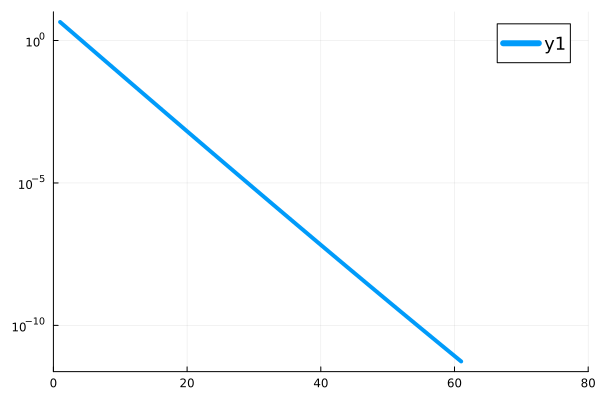

In [3]:
A = [1 1; 1 8]
@show cond(A)
loss(c) = .5 * c' * A * c
grad(c) = A * c

c, chist, lhist = grad_descent(loss, grad, [.9, .9],
    gamma=.22)
plot(lhist, yscale=:log10, xlims=(0, 80))

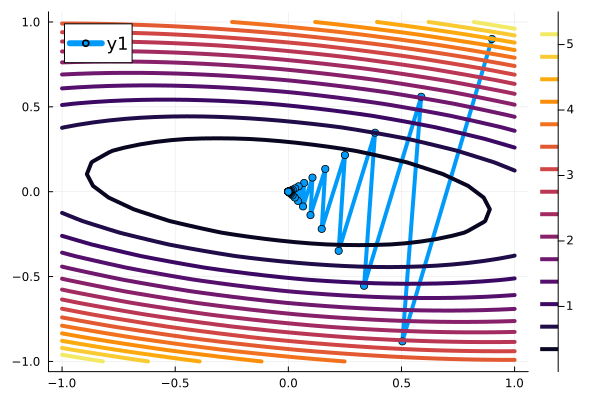

In [4]:
plot(chist[1, :], chist[2, :], marker=:circle)
x = LinRange(-1, 1, 30)
contour!(x, x, (x,y) -> loss([x, y]))

# Chebyshev regression via optimization



In [84]:
x = LinRange(-1, 1, 200)
sigma = 0.5; n = 8
y = runge_noisy(x, sigma)
V = vander_chebyshev(x, n) # or vander_chebyshev
function loss(c)
    r = V * c - y
    .5 * r' * r
end
function grad(c)
    r = V * c - y
    V' * r
end
c, _, lhist = grad_descent(loss, grad, ones(n),
    gamma=0.008)
c

8-element Vector{Float64}:
  0.29884188624714414
 -0.12534353849349622
 -0.24572753809178896
 -0.02811652868862459
  0.16081263947650243
  0.06926222236044383
 -0.11911257591474915
  0.01361840367463182

cond(V) = 3.0429192116168466
cond(V' * V) = 9.259357328426905


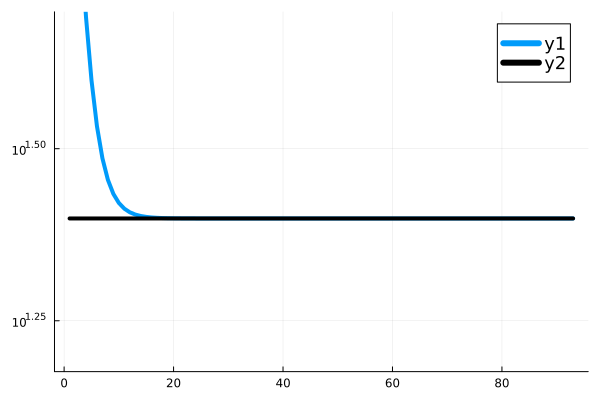

In [85]:
c0 = V \ y
l0 = 0.5 * norm(V * c0 - y)^2
@show cond(V)
@show cond(V' * V)
plot(lhist, yscale=:log10, ylim=(15, 50))
plot!(i -> l0, color=:black)

# Why use QR vs gradient-based optimization?

# Nonlinear models

Instead of the linear model
$$ f(x,c) = V(x) c = c_0 + c_1 \underbrace{x}_{T_1(x)} + c_2 T_2(x) + \dotsb $$
let's consider a rational model with only three parameters
$$ f(x,c) = \frac{1}{c_1 + c_2 x + c_3 x^2} = (c_1 + c_2 x + c_3 x^2)^{-1} . $$
We'll use the same loss function
$$ L(c; x,y) = \frac 1 2 \lVert f(x,c) - y \rVert^2 . $$

We will also need the gradient
$$ \nabla_c L(c; x,y) = \big( f(x,c) - y \big)^T \nabla_c f(x,c) $$
where
\begin{align}
\frac{\partial f(x,c)}{\partial c_1} &= -(c_1 + c_2 x + c_3 x^2)^{-2} = - f(x,c)^2 \\
\frac{\partial f(x,c)}{\partial c_2} &= -(c_1 + c_2 x + c_3 x^2)^{-2} x = - f(x,c)^2 x \\
\frac{\partial f(x,c)}{\partial c_3} &= -(c_1 + c_2 x + c_3 x^2)^{-2} x^2 = - f(x,c)^2 x^2 .
\end{align}

# Fitting a rational function

In [86]:
f(x, c) = 1 ./ (c[1] .+ c[2].*x + c[3].*x.^2)
function gradf(x, c)
    f2 = f(x, c).^2
    [-f2 -f2.*x -f2.*x.^2]
end
function loss(c)
    r = f(x, c) - y
    0.5 * r' * r
end
function gradient(c)
    r = f(x, c) - y
    #@show size(r)
    #@show size(r' * gradf(x, c))
    vec(r' * gradf(x, c))
end

gradient (generic function with 1 method)

c = [1.1253975104528766, -0.10651777197020476, 9.662968441676597]


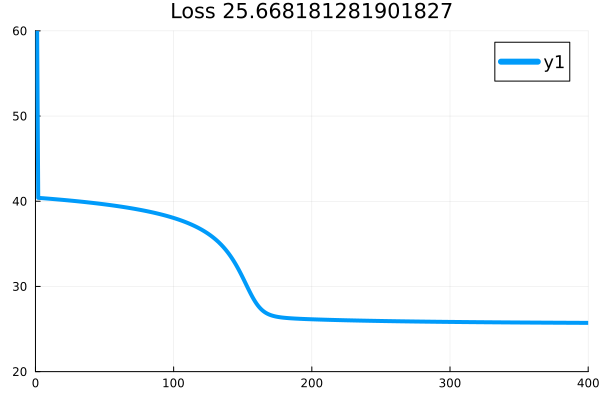

In [87]:
c, _, lhist = grad_descent(loss, gradient, ones(3),
  gamma=8e-2)
@show c
plot(lhist, yscale=:identity, ylim=(20, 60), xlim=(0, 400), title="Loss $(lhist[end])")

# Compare fits on noisy data

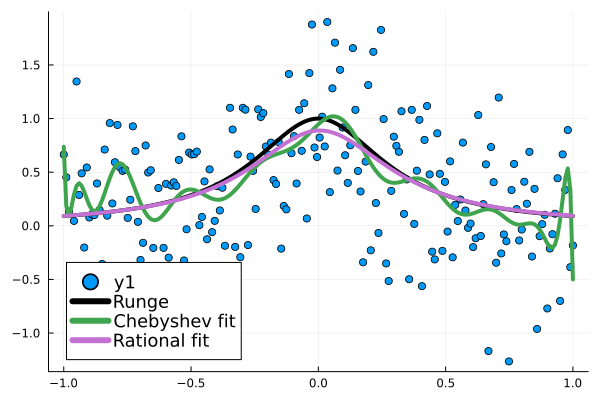

In [88]:
scatter(x, y)
V = vander_chebyshev(x, 20)
plot!(x -> runge(x), color=:black, label="Runge")
plot!(x, V * (V \ y), label="Chebyshev fit")
plot!(x -> f(x, c), label="Rational fit")

# How do we compute those derivatives as the model gets complicated?

$$\lim_{h\to 0} \frac{f(x+h) - f(x)}{h}$$

* How should we choose $h$?

# Taylor series

Classical accuracy analysis assumes that functions are sufficiently smooth, meaning that derivatives exist and Taylor expansions are valid within a neighborhood.  In particular,
$$ f(x+h) = f(x) + f'(x) h + f''(x) \frac{h^2}{2!} + \underbrace{f'''(x) \frac{h^3}{3!} + \dotsb}_{O(h^3)} . $$

The big-$O$ notation is meant in the limit $h\to 0$.  Specifically, a function $g(h) \in O(h^p)$ (sometimes written $g(h) = O(h^p)$) when
there exists a constant $C$ such that
$$ g(h) \le C h^p $$
for all sufficiently *small* $h$.

# Rounding error

We have an additional source of error, *rounding error*, which comes from not being able to compute $f(x)$ or $f(x+h)$ exactly, nor subtract them exactly.  Suppose that we can, however, compute these functions with a relative error on the order of $\epsilon_{\text{machine}}$.  This leads to
$$ \begin{split}
\tilde f(x) &= f(x)(1 + \epsilon_1) \\
\tilde f(x \oplus h) &= \tilde f((x+h)(1 + \epsilon_2)) \\
&= f((x + h)(1 + \epsilon_2))(1 + \epsilon_3) \\
&= [f(x+h) + f'(x+h)(x+h)\epsilon_2 + O(\epsilon_2^2)](1 + \epsilon_3) \\
&= f(x+h)(1 + \epsilon_3) + f'(x+h)x\epsilon_2 + O(\epsilon_{\text{machine}}^2 + \epsilon_{\text{machine}} h)
\end{split}
$$

# Tedious error propagation
$$ \begin{split}
\left\lvert \frac{\tilde f(x+h) \ominus \tilde f(x)}{h} - \frac{f(x+h) - f(x)}{h} \right\rvert &=
  \left\lvert \frac{f(x+h)(1 + \epsilon_3) + f'(x+h)x\epsilon_2 + O(\epsilon_{\text{machine}}^2 + \epsilon_{\text{machine}} h) - f(x)(1 + \epsilon_1) - f(x+h) + f(x)}{h} \right\rvert \\
  &\le \frac{|f(x+h)\epsilon_3| + |f'(x+h)x\epsilon_2| + |f(x)\epsilon_1| + O(\epsilon_{\text{machine}}^2 + \epsilon_{\text{machine}}h)}{h} \\
  &\le \frac{(2 \max_{[x,x+h]} |f| + \max_{[x,x+h]} |f' x| \epsilon_{\text{machine}} + O(\epsilon_{\text{machine}}^2 + \epsilon_{\text{machine}} h)}{h} \\
  &= (2\max|f| + \max|f'x|) \frac{\epsilon_{\text{machine}}}{h} + O(\epsilon_{\text{machine}}) \\
\end{split} $$
where we have assumed that $h \ge \epsilon_{\text{machine}}$.
This error becomes large (relative to $f'$ -- we are concerned with relative error after all)
* $f$ is large compared to $f'$
* $x$ is large
* $h$ is too small

# Automatic step size selection

* Walker and Pernice
* Dennis and Schnabel

In [10]:
diff(f, x; h=1e-8) = (f(x+h) - f(x)) / h

function diff_wp(f, x; h=1e-8)
    """Diff using Walker and Pernice (1998) choice of step"""
    h *= (1 + abs(x))
    (f(x+h) - f(x)) / h
end

x = 1000
diff_wp(sin, x) - cos(x)

-4.139506408429305e-6

# Symbolic differentiation

In [11]:
using Symbolics

@variables x
Dx = Differential(x)

y = sin(x)
Dx(y)

[ Info: Precompiling Symbolics [0c5d862f-8b57-4792-8d23-62f2024744c7](cache misses: incompatible header (1))
[ Info: Precompiling Symbolics [0c5d862f-8b57-4792-8d23-62f2024744c7] (cache misses: incompatible header (2))

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up
┌ Warning: Module PrecompileTools with build ID fafbfcfd-399e-1356-41bb-42c3d1824847 is missing from the cache.
│ This may mean PrecompileTools [aea7be01-6a6a-4083-8856-8a6e6704d82a] does not support precompilation but is imported by a module that does.
└ @ Base loading.jl:2709
┌ Info: Skipping precompilation due to precompilable error. Importing Symbolics [0c5d862f-8b57-4792-8d23-62f2024744c7].
└   exception = Error when precompiling module, potentially caused by a __preco

┌ Warning: Module JLLWrappers with build ID fafbfcfd-e215-6d01-fbb6-af3c7dd41f26 is missing from the cache.
│ This may mean JLLWrappers [692b3bcd-3c85-4b1f-b108-f13ce0eb3210] does not support precompilation but is imported by a module that does.
└ @ Base loading.jl:2709
┌ Info: Skipping precompilation due to precompilable error. Importing SymbolicUtils [d1185830-fcd6-423d-90d6-eec64667417b].
└   exception = Error when precompiling module, potentially caused by a __precompile__(false) declaration in the module.
[ Info: Precompiling SpecialFunctions [276daf66-3868-5448-9aa4-cd146d93841b](cache misses: wrong dep version loaded (1), incompatible header (3))
[ Info: Precompiling SpecialFunctions [276daf66-3868-5448-9aa4-cd146d93841b] (cache misses: wrong dep version loaded (2), incompatible header (6))

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up
┌ Warning: Module JLLWrappers with build ID fafbfcfd-e215-6d01-fbb6-af3c7dd41f26 is missin

┌ Warning: Module StaticArrays with build ID ffffffff-ffff-ffff-98c2-7fc2f2b78d9d is missing from the cache.
│ This may mean StaticArrays [90137ffa-7385-5640-81b9-e52037218182] does not support precompilation but is imported by a module that does.
└ @ Base loading.jl:2709
┌ Info: Skipping precompilation due to precompilable error. Importing AdaptStaticArraysExt [e1699a77-9e31-5da8-bb3e-0a796f95f0a0].
└   exception = Error when precompiling module, potentially caused by a __precompile__(false) declaration in the module.
[ Info: Precompiling PreallocationTools [d236fae5-4411-538c-8e31-a6e3d9e00b46](cache misses: wrong dep version loaded (1))
[ Info: Precompiling PreallocationTools [d236fae5-4411-538c-8e31-a6e3d9e00b46] (cache misses: wrong dep version loaded (2))

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up
┌ Warning: Module Preferences with build ID fafbfcfd-b9c5-47bf-fb18-e2ff55426cfd is missing from the cache.
│ This may mean Pre

[ Info: Precompiling FillArraysStaticArraysExt [de7d94bd-39d2-5101-8358-60ace59cd63e] (cache misses: wrong dep version loaded (2), incompatible header (4))

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up
┌ Warning: Module StaticArrays with build ID ffffffff-ffff-ffff-98c2-7fc2f2b78d9d is missing from the cache.
│ This may mean StaticArrays [90137ffa-7385-5640-81b9-e52037218182] does not support precompilation but is imported by a module that does.
└ @ Base loading.jl:2709
┌ Info: Skipping precompilation due to precompilable error. Importing FillArraysStaticArraysExt [de7d94bd-39d2-5101-8358-60ace59cd63e].
└   exception = Error when precompiling module, potentially caused by a __precompile__(false) declaration in the module.
[ Info: Precompiling StaticArraysExt [6207fee4-2535-5e24-a3ba-6518da1c7d2a](cache misses: wrong dep version loaded (1), incompatible header (2))
[ Info: Precompiling StaticArraysExt [6207fee4-2535-5e24-a3ba-6518da

LoadError: LoadError: MethodError: no method matching _timer_expr(::Module, ::Bool, ::TimerOutputs.TimerOutput, ::String, ::Expr)
The function `_timer_expr` exists, but no method is defined for this combination of argument types.

[0mClosest candidates are:
[0m  _timer_expr([91m::LineNumberNode[39m, [91m::Module[39m, [91m::Bool[39m, [91m::Union{Expr, Symbol, TimerOutputs.TimerOutput}[39m, ::Any)
[0m[90m   @[39m [35mTimerOutputs[39m [90m~/.julia/packages/TimerOutputs/L5q5K/src/[39m[90m[4mTimerOutput.jl:258[24m[39m
[0m  _timer_expr([91m::LineNumberNode[39m, [91m::Module[39m, [91m::Bool[39m, [91m::Union{Expr, Symbol, TimerOutputs.TimerOutput}[39m, ::Any, [91m::Expr[39m)
[0m[90m   @[39m [35mTimerOutputs[39m [90m~/.julia/packages/TimerOutputs/L5q5K/src/[39m[90m[4mTimerOutput.jl:292[24m[39m

in expression starting at /home/jed/.julia/packages/Groebner/GRCIz/src/input-output/input-output.jl:176
in expression starting at /home/jed/.julia/packages/Groe

  Julia 1.12 has introduced more strict world age semantics for global bindings.
  !!! This code may malfunction under Revise.
  !!! This code will error in future versions of Julia.
Hint: Add an appropriate `invokelatest` around the access to this binding.
To make this warning an error, and hence obtain a stack trace, use `julia --depwarn=error`.
  Julia 1.12 has introduced more strict world age semantics for global bindings.
  !!! This code may malfunction under Revise.
  !!! This code will error in future versions of Julia.
Hint: Add an appropriate `invokelatest` around the access to this binding.
To make this warning an error, and hence obtain a stack trace, use `julia --depwarn=error`.
  Julia 1.12 has introduced more strict world age semantics for global bindings.
  !!! This code may malfunction under Revise.
  !!! This code will error in future versions of Julia.
Hint: Add an appropriate `invokelatest` around the access to this binding.
To make this warning an error, and hence o

In [12]:
expand_derivatives(Dx(y))

LoadError: UndefVarError: `expand_derivatives` not defined in `Main`
Suggestion: check for spelling errors or missing imports.
Hint: a global variable of this name also exists in Symbolics.

# Awesome, what about products?

In [13]:
y = x
for _ in 1:1  # try 1:2 or 1:3
    y = cos(y^pi) * log(y)
end
expand_derivatives(Dx(y))

LoadError: UndefVarError: `expand_derivatives` not defined in `Main`
Suggestion: check for spelling errors or missing imports.
Hint: a global variable of this name also exists in Symbolics.

* The size of these expressions can grow **exponentially**

# Hand-coding derivatives

$$ df = f'(x) dx $$

In [14]:
function f(x)
    y = x
    for _ in 1:2
        a = y^pi
        b = cos(a)
        c = log(y)
        y = b * c
    end
    y
end

f(1.9), diff_wp(f, 1.9)

(-1.5346823414986814, -34.032439961925064)

In [15]:
function df(x, dx)
    y = x
    dy = dx
    for _ in 1:2
        a = y ^ pi
        da = pi * y^(pi - 1) * dy
        b = cos(a)
        db = -sin(a) * da
        c = log(y)
        dc = dy / y
        y = b * c
        dy = db * c + b * dc
    end
    y, dy
end

df(1.9, 1)

(-1.5346823414986814, -34.032419599140475)

# We can go the other way

We can differentiate a composition $h(g(f(x)))$ as

\begin{align}
  \operatorname{d} h &= h' \operatorname{d} g \\
  \operatorname{d} g &= g' \operatorname{d} f \\
  \operatorname{d} f &= f' \operatorname{d} x.
\end{align}

What we've done above is called "forward mode", and amounts to placing the parentheses in the chain rule like

$$ \operatorname d h = \frac{dh}{dg} \left(\frac{dg}{df} \left(\frac{df}{dx} \operatorname d x \right) \right) .$$

The expression means the same thing if we rearrange the parentheses,

$$ \operatorname d h = \left( \left( \left( \frac{dh}{dg} \right) \frac{dg}{df} \right) \frac{df}{dx} \right) \operatorname d x .$$

If we introduce a notation $\bar y := \frac{d(\cdot)}{dy}$ and take $\bar h = 1$, this becomes
$$\frac{dh}{dx} =: \bar x = \left( \left( \bar h \frac{dh}{dg} \right) \frac{dg}{df} \right) \frac{df}{dx}$$

# Automatic differentiation

In [16]:
import Zygote

[ Info: Precompiling Zygote [e88e6eb3-aa80-5325-afca-941959d7151f](cache misses: wrong dep version loaded (1), incompatible header (3))
[ Info: Precompiling Zygote [e88e6eb3-aa80-5325-afca-941959d7151f] (cache misses: wrong dep version loaded (2), incompatible header (6))

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up
┌ Warning: Module SpecialFunctions with build ID ffffffff-ffff-ffff-f1c5-17c52054e4a4 is missing from the cache.
│ This may mean SpecialFunctions [276daf66-3868-5448-9aa4-cd146d93841b] does not support precompilation but is imported by a module that does.
└ @ Base loading.jl:2709
┌ Info: Skipping precompilation due to precompilable error. Importing Zygote [e88e6eb3-aa80-5325-afca-941959d7151f].
└   exception = Error when precompiling module, potentially caused by a __precompile__(false) declaration in the module.
[ Info

In [17]:
Zygote.gradient(f, 1.9)

(-34.03241959914049,)

In [18]:
g(x) = exp(x) + x^2
@code_llvm Zygote.gradient(g, 1.9)

; Function Signature: gradient(typeof(Main.g), Float64)
;  @ /home/jed/.julia/packages/Zygote/zowwZ/src/compiler/interface.jl:146 within `gradient`
define [1 x double] @julia_gradient_75596(double %"args[1]::Float64") #0 {
top:
;  @ /home/jed/.julia/packages/Zygote/zowwZ/src/compiler/interface.jl:147 within `gradient`
; ┌ @ /home/jed/.julia/packages/Zygote/zowwZ/src/compiler/interface.jl:88 within `pullback` @ /home/jed/.julia/packages/Zygote/zowwZ/src/compiler/interface.jl:90
; │┌ @ In[18]:1 within `g`
; ││┌ @ /home/jed/.julia/packages/Zygote/zowwZ/src/compiler/interface2.jl:91 within `_pullback`
; │││┌ @ /home/jed/.julia/packages/Zygote/zowwZ/src/compiler/interface2.jl within `macro expansion`
; ││││┌ @ /home/jed/.julia/packages/Zygote/zowwZ/src/compiler/chainrules.jl:224 within `chain_rrule`
; │││││┌ @ /home/jed/.julia/packages/ChainRulesCore/d9BUN/src/rules.jl:137 within `rrule` @ /home/jed/.julia/packages/ChainRules/HzFUp/src/rulesets/Base/fastmath_able.jl:56
        %0 = call dou